In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from geopy.distance import geodesic

In [7]:
data = pd.read_excel("anomalies_corrected_data.xlsx", sheet_name="Data")
data_dist = data.copy()
print(data["step"])

0            1
1            2
2            3
3            4
4            5
         ...  
15870    15871
15871    15872
15872    15873
15873    15874
15874    15875
Name: step, Length: 15875, dtype: int64


In [8]:
first_points = []
second_points = []
indexes = []

for var in range(len(data)):
    if var == (len(data) - 1):
        break
    if data.loc[var]["latitude"] == data.loc[var + 1]["latitude"] and data.loc[var]["longitude"] == data.loc[var + 1]["longitude"]:
        continue
    else:
        point1 = (data.loc[var]["latitude"], data.loc[var]["longitude"])
        point2 = (data.loc[var + 1]["latitude"], data.loc[var + 1]["longitude"])
        first_points.append(point1)
        second_points.append(point2)
        indexes.append(var)

dist = []
f = 0
for i in range(len(data)):
    if i in indexes:
            dist.append(geodesic(first_points[f], second_points[f]).km)
            f = f + 1
    else:
        dist.append(0)
data_dist["distances"] = dist

In [9]:
with pd.option_context('display.max_rows', None):
    print(data_dist["distances"].value_counts())

distances
0.000000      14214
0.544123         43
0.771487         37
2.081843         32
1.061901         28
1.023276         27
0.530811         25
48.067306        25
0.707071         24
1.468333         22
0.215170         20
1.690184         18
6.193833         18
2.332611         17
0.521028         17
1.039587         16
1.018939         16
4.287392         14
12.444340        14
0.769717         14
0.173852         14
2.084297         13
49.606616        13
1.170988         12
1.761097         11
1.825872         11
0.492924         11
2.678949         11
0.853245         10
1.707608         10
0.711893         10
1.229976         10
2.929208         10
0.563741         10
9.977555          9
1.117511          9
1.074147          9
2.729884          9
10.181311         9
8.505576          9
2.660531          8
3.008992          8
1.901443          8
3.246855          8
1.335795          8
12.211036         8
0.509882          8
3.523312          8
2.437347          7
2.776412  

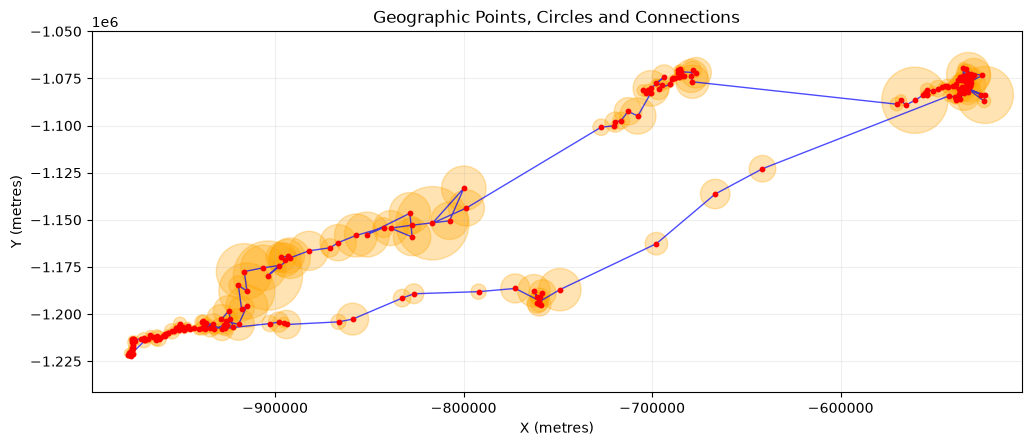

In [11]:

from pyproj import Transformer
import matplotlib.pyplot as plt
import random

# 1. Select unique geographic locations
sub_data = data.drop_duplicates(subset=["latitude", "longitude"]).head(600)

# 2. Extract columns
latitude = sub_data["latitude"]
longitude = sub_data["longitude"]
outer_radius = sub_data["outer_radius"]

# 3. Transform coordinates from EPSG:4326 to EPSG:5514
transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:5514",
    always_xy=True
)

x_vals, y_vals = transformer.transform(
    longitude.to_numpy(),
    latitude.to_numpy()
)

# 4. Create figure
fig, ax = plt.subplots(figsize=(12, 10))

# 5. Draw circles around all points
for i in range(len(sub_data)):

    x = x_vals[i]
    y = y_vals[i]
    r = outer_radius.iloc[i]

    circle = plt.Circle(
        (x, y),
        radius=r,
        facecolor="orange",
        alpha=0.3,
        edgecolor="orange"
    )

    ax.add_patch(circle)

# 6. Connect consecutive points
ax.plot(x_vals, y_vals, color="blue", linewidth=1, alpha=0.7, zorder=2)

# 7. Draw point locations
ax.scatter(x_vals, y_vals, color="red", s=10, zorder=3)

# 8. Configure plot boundaries
max_radius = outer_radius.max()

ax.set_xlim(min(x_vals) - max_radius, max(x_vals) + max_radius)

ax.set_ylim(min(y_vals) - max_radius, max(y_vals) + max_radius)

ax.set_aspect("equal")
ax.set_xlabel("X (metres)")
ax.set_ylabel("Y (metres)")
ax.set_title("Geographic Points, Circles and Connections")
ax.grid(alpha=0.2)

plt.show()
